---
title: "Practice Activity 11-1: Introduction to Classification"
author: "Shiqi Wu"
format:
  html:
    embed-resources: true
    html-math-method: mathml
    code-overflow: wrap
---

# Practice Activity 11-1: Introduction to Classification

**Name:** Shiqi Wu

# Introduction to Classification

In [21]:
import pandas as pd
import numpy as np

## Classifying Tropical Storms

The "storms" data set contains data on tropical storms since 1975. Suppose we want to use this data to train a classification model that predicts whether or not a storm is a hurricane based on its wind speed and pressure.


In [22]:
df_storms = pd.read_csv("https://raw.githubusercontent.com/kevindavisross/data301/main/data/storms.csv")
df_storms["hurricane"] = (df_storms["status"] == "hurricane")
df_storms


,name,year,month,day,hour,lat,long,status,category,wind,pressure,tropicalstorm_force_diameter,hurricane_force_diameter,hurricane
0,Amy,1975,6,27,0,27.5,-79.0,tropical depression,NaN,25,1013,NaN,NaN,False
1,Amy,1975,6,27,6,28.5,-79.0,tropical depression,NaN,25,1013,NaN,NaN,False
2,Amy,1975,6,27,12,29.5,-79.0,tropical depression,NaN,25,1013,NaN,NaN,False
3,Amy,1975,6,27,18,30.5,-79.0,tropical depression,NaN,25,1013,NaN,NaN,False
4,Amy,1975,6,28,0,31.5,-78.8,tropical depression,NaN,25,1012,NaN,NaN,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
19061,Wanda,2021,11,7,0,37.4,-37.4,tropical storm,NaN,35,1003,60.0,0.0,False
19062,Wanda,2021,11,7,6,38.1,-36.4,tropical storm,NaN,35,1004,60.0,0.0,False
19063,Wanda,2021,11,7,12,39.2,-34.9,other low,NaN,35,1006,90.0,0.0,False
19064,Wanda,2021,11,7,18,40.9,-32.8,other low,NaN,40,1006,90.0,0.0,False


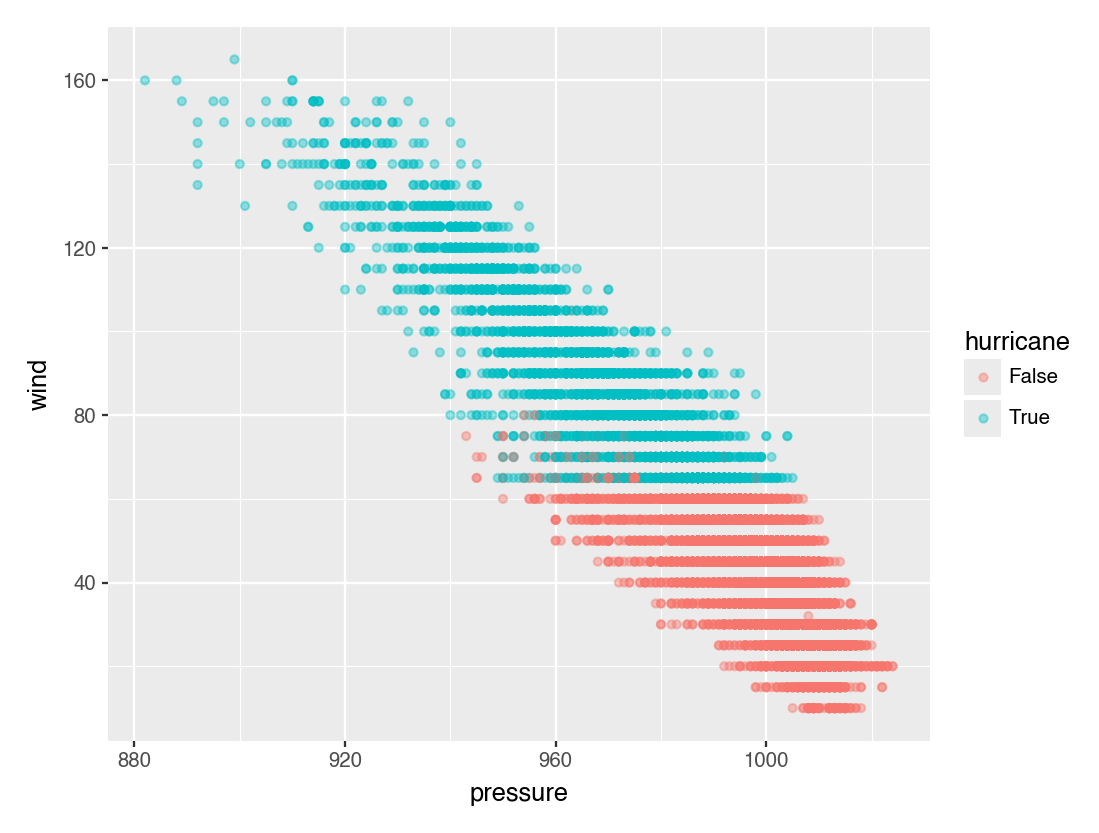

In [23]:
from plotnine import *

(
    ggplot(
        df_storms,
        aes(x="pressure", y="wind", color="hurricane")
    )
    + geom_point(alpha=0.4)
)

1. Inspect the scatterplot above. Suggest a simple classification rule that you suspect will have both high precision and high recall for the hurriance class based on the training data. **Without doing any coding, specify your rule and explain your reasoning.** This is NOT asking you to do nearest neighbors. Rather suggest a simple classification rule based on what you see in the plot.

**Answer:** We can predict that a storm is a hurricane if its wind speed is greater than 60, and predict that it is not a hurricane otherwise. Almost all hurricane points are above this cutoff, so we expect high recall. Most points above the cutoff are hurricanes, so we also expect high precision. A few non-hurricane points are above the cutoff and would be false positives.

**DISCUSS WITH YOUR PARTNER.**

2. For each of the following **compute the value and write a clearly worded sentence interpreting the value as a percentage in context.** Again, this is NOT asking you to fit a nearest neighbors model. You can write code, but you should only need to write basic code to make your predictions and get relevant counts from the training data. You can compute things like fractions by hand.

  a. training accuracy  
  b. training precision for the hurricane class  
  c. training recall for the hurricane class  
  d. training F1 score for the hurricane class  
  e. training precision for the non-hurricane class    
  f. training precision for the non-hurricane class  
  g. training F1 score for the non-hurricane class  

In [24]:
pred_hurricane = df_storms["wind"] > 60

pd.crosstab(
    df_storms["hurricane"],
    pred_hurricane,
    rownames=["Actual hurricane"],
    colnames=["Predicted hurricane"]
)

Predicted hurricane,False,True
Actual hurricane,,
False,14254,128
True,0,4684


**DISCUSS WITH YOUR PARTNER.**

In [25]:
training_accuracy = (14254 + 4684) / (14254 + 128 + 0 + 4684)
training_accuracy * 100

99.32864785482009

**Answer:** (a) The training accuracy is 99.33%. Our rule correctly classifies 18,938 of the 19,066 storm observations as hurricanes or non-hurricanes.

In [26]:
hurricane_precision = 4684 / (128 + 4684)
hurricane_precision * 100

97.3399833748961

**Answer:** (b) The training precision for hurricanes is 97.34%. Among the storm observations predicted to be hurricanes, 97.34% are actually hurricanes.

In [27]:
hurricane_recall = 4684 / (4684 + 0)
hurricane_recall * 100

100.0

**Answer:** (c) The training recall for hurricanes is 100%. Our rule correctly identifies all 4,684 actual hurricane observations in the training data.

In [28]:
hurricane_f1 = (
    2 * hurricane_precision * hurricane_recall
    / (hurricane_precision + hurricane_recall)
)
hurricane_f1 * 100

98.65206402695873

**Answer:** (d) The training F1 score for hurricanes is 98.65%. This is the harmonic mean of the hurricane precision of 97.34% and recall of 100%, showing strong performance on both measures.

In [29]:
non_hurricane_precision = 14254 / (14254 + 0)
non_hurricane_precision * 100

100.0

**Answer:** (e) The training precision for non-hurricanes is 100%. All 14,254 storm observations predicted to be non-hurricanes are actually non-hurricanes.

In [30]:
non_hurricane_recall = 14254 / (14254 + 128)
non_hurricane_recall * 100

99.10999860937282

**Answer:** (f) The question repeats non-hurricane precision, which is 100%. If recall was intended, the training recall for non-hurricanes is 99.11%. Our rule correctly identifies 14,254 of the 14,382 actual non-hurricane observations.

In [31]:
non_hurricane_f1 = (
    2 * non_hurricane_precision * non_hurricane_recall
    / (non_hurricane_precision + non_hurricane_recall)
)
non_hurricane_f1 * 100

99.55301019695489

**Answer:** (g) The training F1 score for non-hurricanes is 99.55%. This is the harmonic mean of the non-hurricane precision of 100% and recall of 99.11%, showing strong performance on both measures.

3. The "status" variable contains further breakdown of the non-hurricane class. Suppose we fit a **10-nearest neighbors** classification model for predicting status from wind speed and pressure. Without doing any coding, what status would the model predict for a storm with a pressure of 975 and wind speed of 39? **Explain your reasoning without doing any coding**. Hint: look at the scatterplot below, but be careful since some points are superimposed.

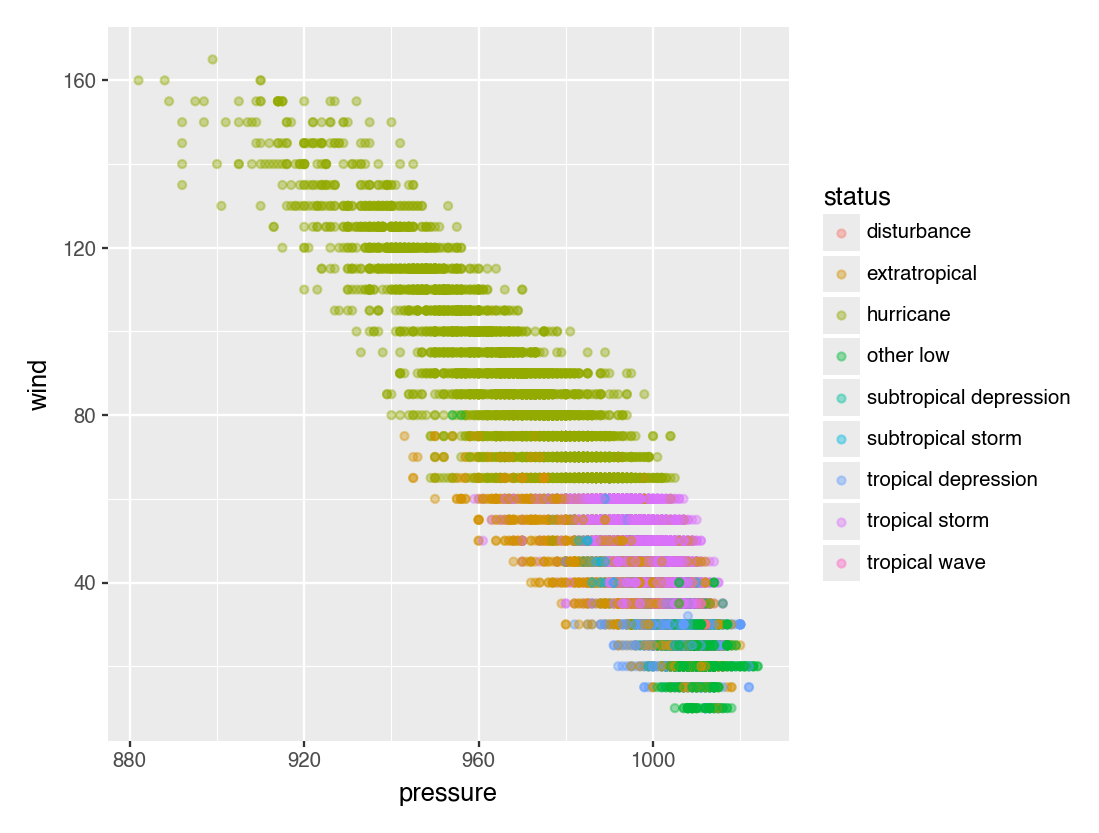

In [32]:
(
    ggplot(
        df_storms,
        aes(x="pressure", y="wind", color="status")
    )
    + geom_point(alpha=0.4)
)

**Answer:** We would expect the 10-nearest neighbors model to predict extratropical for a storm with a pressure of 975 and wind speed of 39. The nearby points appear to be mostly extratropical, so this class would likely receive the most votes among the 10 nearest observations. Some observations overlap in the plot, so the visible points do not show every observation separately.

**DISCUSS WITH YOUR PARTNER.**

4. Suppose we fit a **10-nearest neighbors** classification model for predicting status from wind speed and pressure. Without doing any coding, which classes do you think would have the lowest recall based on the training data? **Explain your reasoning without doing any coding.** Hint: look at the scatterplot above, but be careful since some points are superimposed.

**Answer:** We would expect disturbance, tropical wave, subtropical depression, and subtropical storm to have the lowest recall. These classes appear less common and overlap with other classes in wind speed and pressure. Their observations may have more neighbors from other classes, so the 10-nearest neighbors model may predict another class instead. This would cause many observations from these classes to be missed and lower their recall.

**DISCUSS WITH YOUR PARTNER.**

## Practice Activity Titanic Data

We'll use $k$-nearest neighbors to predict who survives based on age, sex, and class.

In [33]:
df_titanic = pd.read_csv("https://dlsun.github.io/pods/data/titanic.csv ")

# drop the NaN for age since we're using it as a predictor
df_titanic = df_titanic.dropna(subset = ["age"])

df_titanic

,name,gender,age,class,embarked,country,ticketno,fare,survived
0,"Abbing, Mr. Anthony",male,42.0,3rd,S,United States,5547.0,7.11,0
1,"Abbott, Mr. Eugene Joseph",male,13.0,3rd,S,United States,2673.0,20.05,0
2,"Abbott, Mr. Rossmore Edward",male,16.0,3rd,S,United States,2673.0,20.05,0
3,"Abbott, Mrs. Rhoda Mary 'Rosa'",female,39.0,3rd,S,England,2673.0,20.05,1
4,"Abelseth, Miss. Karen Marie",female,16.0,3rd,S,Norway,348125.0,7.13,1
...,...,...,...,...,...,...,...,...,...
2202,"Wynn, Mr. Walter",male,41.0,deck crew,B,England,NaN,NaN,1
2203,"Yearsley, Mr. Harry",male,40.0,victualling crew,S,England,NaN,NaN,1
2204,"Young, Mr. Francis James",male,32.0,engineering crew,S,England,NaN,NaN,0
2205,"Zanetti, Sig. Minio",male,20.0,restaurant staff,S,England,NaN,NaN,0


1\. Train a 10-nearest neighbors model to predict whether or not a passenger on the Titanic survived, using their age, sex, and class as features.

In [34]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.neighbors import KNeighborsClassifier

X_titanic = df_titanic[["age", "gender", "class"]]
y_titanic = df_titanic["survived"]

preprocessor = ColumnTransformer([
    ("age", StandardScaler(), ["age"]),
    ("categories", OneHotEncoder(handle_unknown="ignore"),
     ["gender", "class"])
])

titanic_model = Pipeline([
    ("preprocess", preprocessor),
    ("knn", KNeighborsClassifier(n_neighbors=10))
])

titanic_model.fit(X_titanic, y_titanic)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators ` for more details.","[('preprocess', ...), ('knn', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing `.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('age', ...), ('categories', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers

**Answer:** We fitted a 10-nearest neighbors classification model using age, gender, and class to predict survival. We standardized age and used one-hot encoding for gender and class. The target is survived, where 1 represents survival and 0 represents non-survival.

2\. Use your model to predict whether a 20-year old female in first-class would survive. What about a 20-year old female in third-class? What are the predicted probabilities for each?

In [35]:
new_passengers = pd.DataFrame({
    "age": [20, 20],
    "gender": ["female", "female"],
    "class": ["1st", "3rd"]
})

predictions = titanic_model.predict(new_passengers)
probabilities = titanic_model.predict_proba(new_passengers)

prediction_results = new_passengers.copy()
prediction_results["predicted_survival"] = predictions
prediction_results["survival_probability"] = probabilities[:, 1]

prediction_results

,age,gender,class,predicted_survival,survival_probability
0,20,female,1st,1,1.0
1,20,female,3rd,0,0.2


**Answer:** Our model predicts that a 20-year-old female in first class would survive, with a predicted survival probability of 100%. For a 20-year-old female in third class, the model predicts non-survival, with a predicted survival probability of 20%. These probabilities are based on the survival outcomes of the 10 nearest neighbors and do not guarantee an individual's outcome.

3\. Calculate and interpret the training precision, recall, and F1 score for predicting survivors.

In [36]:
from sklearn.metrics import precision_score, recall_score, f1_score

titanic_train_pred = titanic_model.predict(X_titanic)

survivor_precision = precision_score(
    y_titanic, titanic_train_pred, pos_label=1
)
survivor_recall = recall_score(
    y_titanic, titanic_train_pred, pos_label=1
)
survivor_f1 = f1_score(
    y_titanic, titanic_train_pred, pos_label=1
)

pd.Series({
    "Precision": survivor_precision,
    "Recall": survivor_recall,
    "F1": survivor_f1
}).mul(100).round(2).to_frame("Training score (%)")

,Training score (%)
Precision,84.98
Recall,53.31
F1,65.51


**Answer:** The training precision for survivors is 84.98%, meaning that 84.98% of those predicted to survive actually survived. The training recall is 53.31%, meaning that our model correctly identifies 53.31% of the actual survivors. The training F1 score is 65.51%, which is the harmonic mean of precision and recall. Our model has relatively high precision but misses many actual survivors.

4\. Calculate and interpret the training precision, recall, and F1 score for predicting non-survivors.

In [37]:
non_survivor_precision = precision_score(
    y_titanic, titanic_train_pred, pos_label=0
)
non_survivor_recall = recall_score(
    y_titanic, titanic_train_pred, pos_label=0
)
non_survivor_f1 = f1_score(
    y_titanic, titanic_train_pred, pos_label=0
)

pd.Series({
    "Precision": non_survivor_precision,
    "Recall": non_survivor_recall,
    "F1": non_survivor_f1
}).mul(100).round(2).to_frame("Training score (%)")

,Training score (%)
Precision,81.13
Recall,95.52
F1,87.73


**Answer:** The training precision for non-survivors is 81.13%, meaning that 81.13% of those predicted not to survive actually did not survive. The training recall is 95.52%, meaning that our model correctly identifies 95.52% of the actual non-survivors. The training F1 score is 87.73%, which is the harmonic mean of precision and recall. Our model identifies most non-survivors but also predicts non-survival for some actual survivors.

5\. Since there are only two classes (survived or not) the model predicts survival if the predicted probability of survival is $0.5$ or higher. Change the threshold from 0.5 to 0.8 and compute the precision and recall for survivors and the non-survivors. How do the values compare to those with the threshold of 0.5?

In [38]:
survival_prob = titanic_model.predict_proba(X_titanic)[:, 1]

threshold_results = []

for threshold in [0.5, 0.8]:
    pred_at_threshold = (survival_prob >= threshold).astype(int)

    for label, class_name in [(1, "Survivors"), (0, "Non-survivors")]:
        threshold_results.append({
            "Threshold": threshold,
            "Class": class_name,
            "Precision (%)": 100 * precision_score(
                y_titanic, pred_at_threshold, pos_label=label
            ),
            "Recall (%)": 100 * recall_score(
                y_titanic, pred_at_threshold, pos_label=label
            )
        })

pd.DataFrame(threshold_results).round(2)

,Threshold,Class,Precision (%),Recall (%)
0,0.5,Survivors,78.05,62.03
1,0.5,Non-survivors,83.54,91.70
2,0.8,Survivors,91.90,41.49
3,0.8,Non-survivors,77.92,98.26


**Answer:** When the threshold increases from 0.5 to 0.8, survivor precision increases from 78.05% to 91.90%, while survivor recall decreases from 62.03% to 41.49%. Our model becomes more selective when predicting survival, but it misses more actual survivors.

For non-survivors, precision decreases from 83.54% to 77.92%, while recall increases from 91.70% to 98.26%. Our model identifies more actual non-survivors but also predicts non-survival for more actual survivors.

We used probabilities greater than or equal to each threshold. The 0.5 results differ from Questions 3 and 4 because the default KNN prediction assigns a probability of exactly 0.5 to non-survival, while this question's rule assigns it to survival.

6\. Plot the precision-recall curve for the survivors. Interpret what you see.

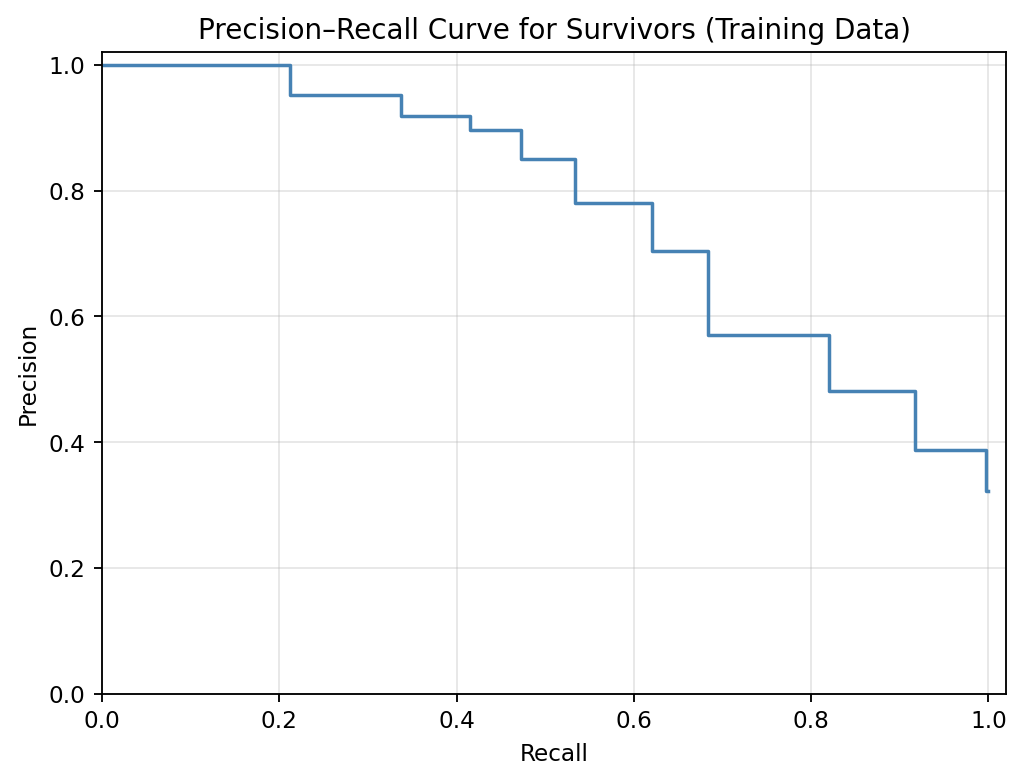

In [39]:
import matplotlib.pyplot as plt
from sklearn.metrics import precision_recall_curve

precisions, recalls, thresholds = precision_recall_curve(
    y_titanic, survival_prob, pos_label=1
)

plt.figure(figsize=(7, 5))
plt.step(recalls, precisions, where="post", color="steelblue")
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision–Recall Curve for Survivors (Training Data)")
plt.xlim(0, 1.02)
plt.ylim(0, 1.02)
plt.grid(alpha=0.3)
plt.show()

**Answer:** The curve shows a trade-off between precision and recall for survivors. Precision is high when the model identifies only a smaller share of actual survivors. As recall increases, precision generally decreases because more non-survivors are incorrectly predicted to survive. For example, a threshold of 0.8 gives 91.90% precision and 41.49% recall, while a threshold of 0.5 gives 78.05% precision and 62.03% recall. The steps reflect the limited probability values produced by the 10-nearest neighbors model. These results describe performance on the training data.

7\. Plot the precision-recall curve for non-survivors. Interpret what you see.

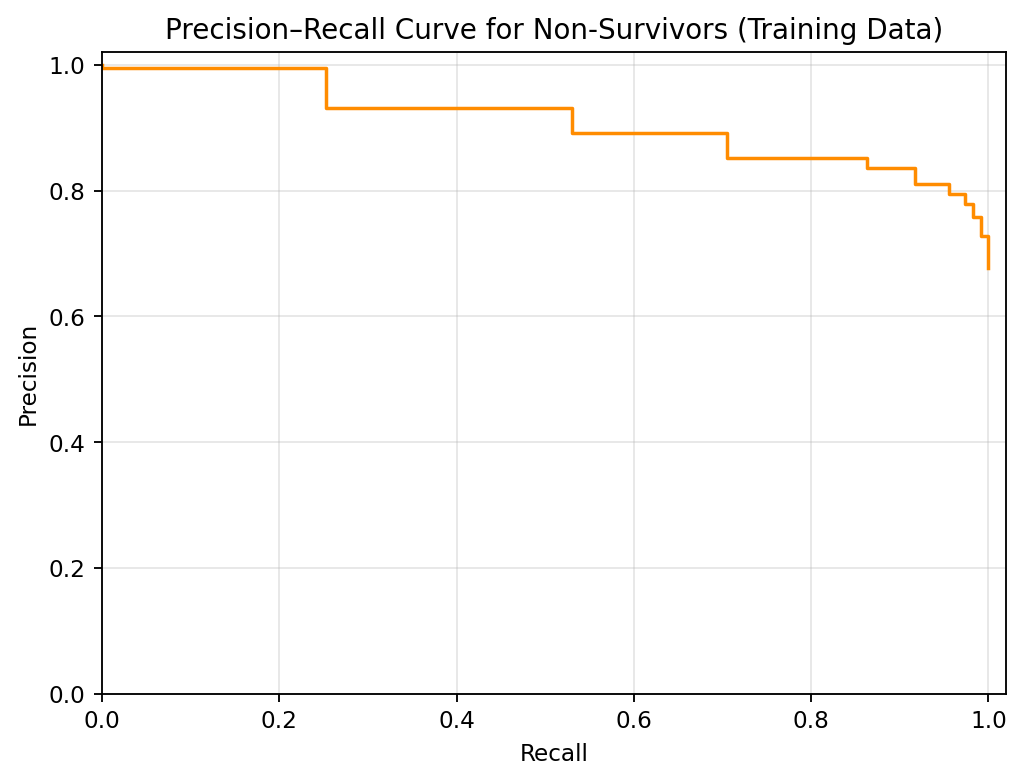

In [40]:
non_survival_prob = titanic_model.predict_proba(X_titanic)[:, 0]

non_survivor_precisions, non_survivor_recalls, _ = precision_recall_curve(
    y_titanic, non_survival_prob, pos_label=0
)

plt.figure(figsize=(7, 5))
plt.step(
    non_survivor_recalls,
    non_survivor_precisions,
    where="post",
    color="darkorange"
)
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision–Recall Curve for Non-Survivors (Training Data)")
plt.xlim(0, 1.02)
plt.ylim(0, 1.02)
plt.grid(alpha=0.3)
plt.show()

**Answer:** The curve shows that our model can identify a large share of actual non-survivors while keeping relatively high precision. With the default predictions from Question 4, precision is 81.13% and recall is 95.52%. Increasing recall further generally reduces precision because more actual survivors are incorrectly predicted not to survive. The steps reflect the limited probability values produced by the 10-nearest neighbors model. These results describe performance on the training data.